## Replication Sample Analysis

Batch 1: 10 → 9 subjects
Batch 2: 50 → 39 subjects
Batch 3: 172 → 151 subjects

Total subjects: 199
Unique fileIDs: 199
Duplicate fileIDs: 0
SPEARMAN CORRELATION RESULTS


,Predictor,Parameter,N,Spearman_rho,p,p_fdr
0,ELU Factor 1,alpha,197,-0.1252,0.0795,0.5301
1,ELU Factor 1,gamma_base,197,0.0552,0.4410,0.8545
2,ELU Factor 1,gamma_coef,197,0.1920,0.0069,0.0862
3,ELU Factor 1,beta,197,-0.0293,0.6827,0.8817
4,ELU Factor 1,epsilon,197,-0.0355,0.6207,0.8817
5,ELU Factor 2,alpha,197,-0.0051,0.9437,0.9497
6,ELU Factor 2,gamma_base,197,-0.0662,0.3552,0.7815
7,ELU Factor 2,gamma_coef,197,0.0236,0.7418,0.8817
8,ELU Factor 2,beta,197,-0.0249,0.7278,0.8817
9,ELU Factor 2,epsilon,197,0.0101,0.8879,0.9497


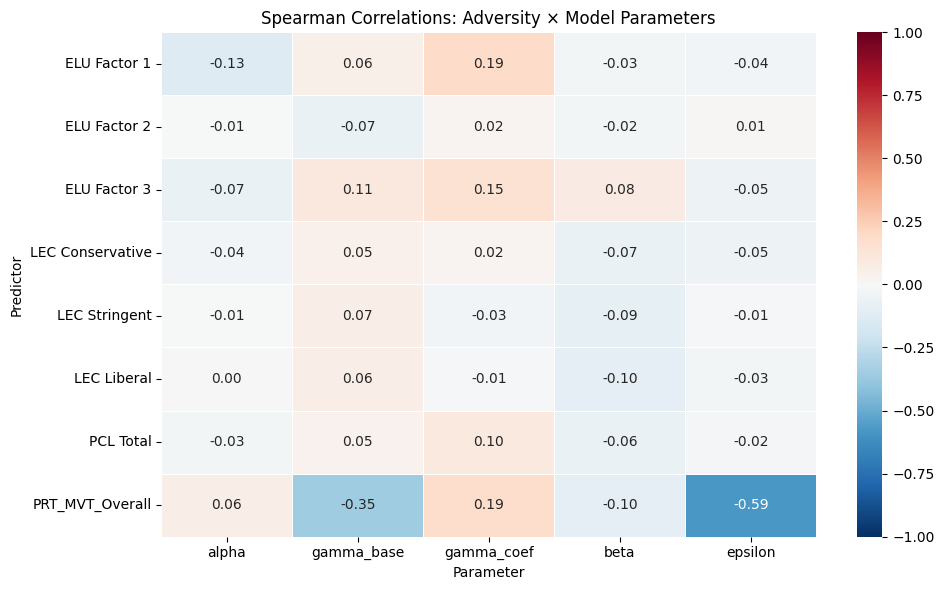

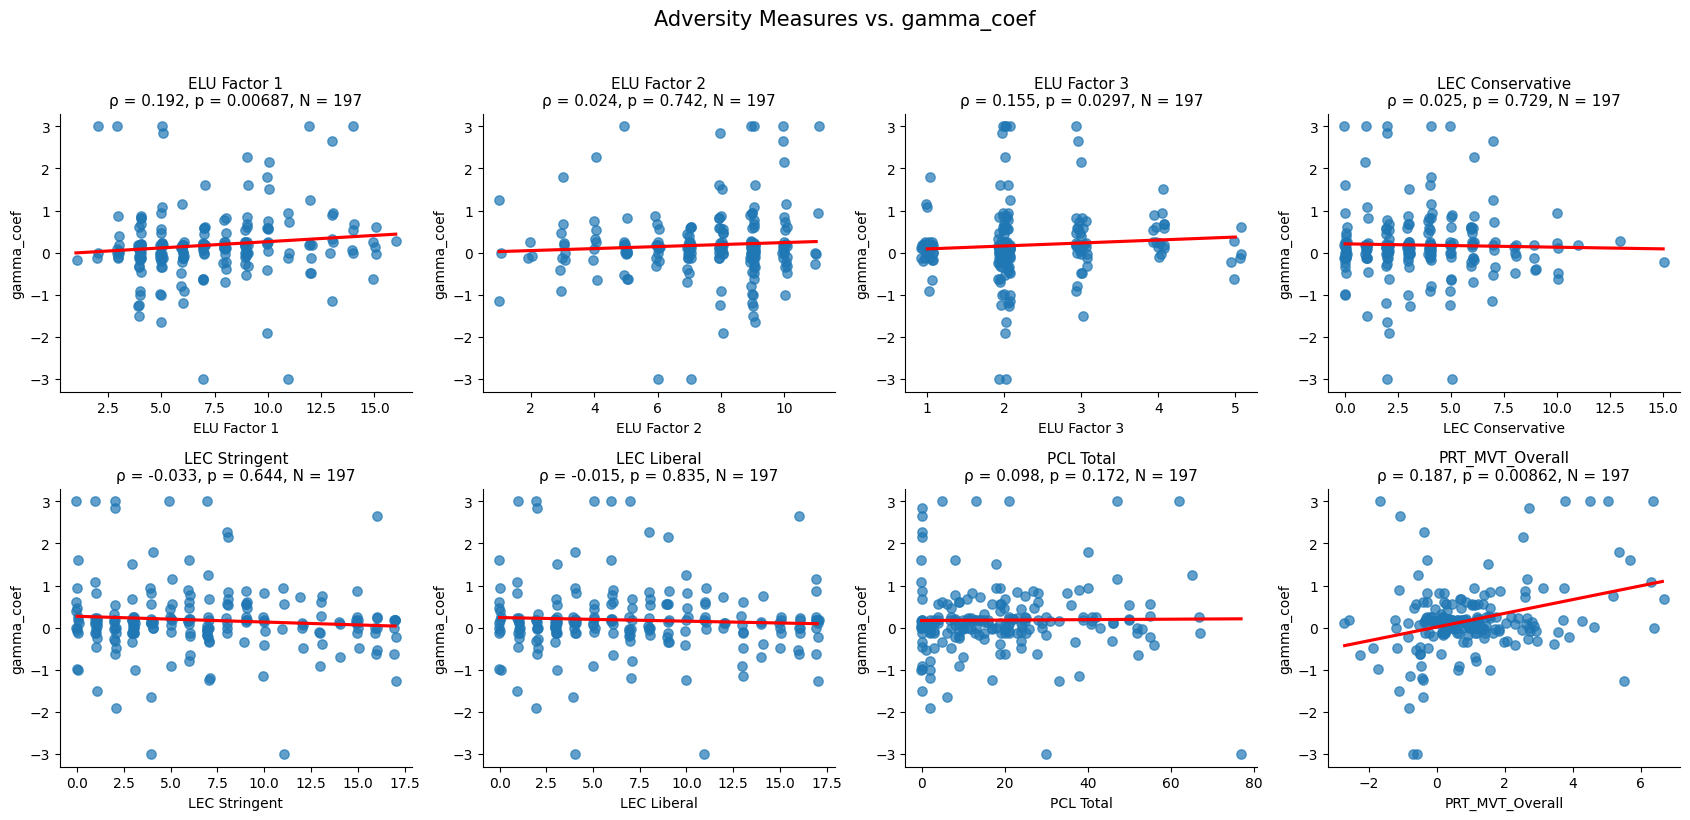


GAMMA_COEF CORRELATION SUMMARY


,Predictor,Parameter,N,Spearman_rho,p,p_fdr
2,ELU Factor 1,gamma_coef,197,0.1920,0.0069,0.0862
37,PRT_MVT_Overall,gamma_coef,197,0.1867,0.0086,0.0862
12,ELU Factor 3,gamma_coef,197,0.1549,0.0297,0.2376
32,PCL Total,gamma_coef,197,0.0976,0.1725,0.6969
22,LEC Stringent,gamma_coef,197,-0.0332,0.6435,0.8817
17,LEC Conservative,gamma_coef,197,0.0249,0.7287,0.8817
7,ELU Factor 2,gamma_coef,197,0.0236,0.7418,0.8817
27,LEC Liberal,gamma_coef,197,-0.0150,0.8346,0.9458


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

# ============================================================
# 1. Load data
# ============================================================

data_dir = Path(
    r"C:\Users\zyfxl\OneDrive - UC Irvine\UCI\CCNL Lab\Foraging Task Overview"
    r"\foraging_MQLP-main\foraging_MQLP-main\replication sample\processed data"
)

# Excluded subject numbers by batch
exclude = {
    1: [8],
    2: [48, 49, 43, 39, 24, 30, 41, 16, 29, 38, 46],
    3: [98, 169, 106, 138, 12, 108, 78, 79, 80, 19,
        149, 152, 91, 124, 157, 95, 16, 61, 98, 112,
        121, 133, 140, 149, 150, 95]
}

# Load, exclude, and combine
dfs = []

for batch in [1, 2, 3]:
    df_batch = pd.read_csv(
        data_dir / f"batch{batch}" / "replication_questionnaires.csv"
    )

    n_before = len(df_batch)
    df_batch = df_batch[~df_batch["sub_num"].isin(exclude[batch])].copy()

    print(f"Batch {batch}: {n_before} → {len(df_batch)} subjects")
    dfs.append(df_batch)

df = pd.concat(dfs, ignore_index=True)

# Check combined dataset
print("\nTotal subjects:", len(df))
print("Unique fileIDs:", df["fileID"].nunique())
print("Duplicate fileIDs:", df["fileID"].duplicated().sum())

# Save
df.to_csv(data_dir / "replication_questionnaires_combined.csv", index=False)

# ============================================================
# 2. Variables
# ============================================================

predictors = {
    "FA_factor_1": "ELU Factor 1",
    "FA_factor_2": "ELU Factor 2",
    "FA_factor_3": "ELU Factor 3",
    "LEC_Conservative": "LEC Conservative",
    "LEC_Stringent": "LEC Stringent",
    "LEC_Liberal": "LEC Liberal",
    "PCL_Total": "PCL Total",
    "PRT_MVT_Overall" : "PRT_MVT_Overall",

}

parameters = [
    "alpha",
    "gamma_base",
    "gamma_coef",
    "beta",
    "epsilon"
]

# Verify columns
required = list(predictors) + parameters
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# ============================================================
# 3. Spearman correlation analysis
# ============================================================

results = []

for pred, label in predictors.items():
    for param in parameters:

        data = df[[pred, param]].apply(
            pd.to_numeric, errors="coerce"
        ).dropna()

        n = len(data)

        if (n >= 4 and
            data[pred].nunique() > 1 and
            data[param].nunique() > 1):

            rho, p = spearmanr(data[pred], data[param])

        else:
            rho, p = np.nan, np.nan

        results.append({
            "Predictor": label,
            "Parameter": param,
            "N": n,
            "Spearman_rho": rho,
            "p": p
        })

corr_df = pd.DataFrame(results)

# FDR correction across all valid correlations
corr_df["p_fdr"] = np.nan

valid = corr_df["p"].notna()

if valid.any():
    corr_df.loc[valid, "p_fdr"] = multipletests(
        corr_df.loc[valid, "p"],
        method="fdr_bh"
    )[1]

print("SPEARMAN CORRELATION RESULTS")
display(corr_df.round(4))

# corr_df.to_csv(
#     data_dir / "replication_spearman_correlations.csv",
#     index=False
# )

# ============================================================
# 4. Correlation heatmap
# ============================================================

rho_matrix = corr_df.pivot(
    index="Predictor",
    columns="Parameter",
    values="Spearman_rho"
)

rho_matrix = rho_matrix.reindex(
    index=list(predictors.values()),
    columns=parameters
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    rho_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Spearman Correlations: Adversity × Model Parameters")
plt.tight_layout()

# plt.savefig(
#     data_dir / "replication_correlation_heatmap.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

# ============================================================
# 5. Individual scatterplots
# ============================================================

# Change to another parameter if desired
target_param = "gamma_coef"

fig, axes = plt.subplots(2, 4, figsize=(17, 8))
axes = axes.flatten()

for i, (pred, label) in enumerate(predictors.items()):

    ax = axes[i]

    data = df[[pred, target_param]].apply(
        pd.to_numeric, errors="coerce"
    ).dropna()

    sns.regplot(
        data=data,
        x=pred,
        y=target_param,
        ax=ax,
        scatter_kws={"alpha": 0.7, "s": 45},
        line_kws={"color": "red"},
        x_jitter=0.08,
        ci=None
    )

    result = corr_df[
        (corr_df["Predictor"] == label) &
        (corr_df["Parameter"] == target_param)
    ].iloc[0]

    rho = result["Spearman_rho"]
    p = result["p"]
    n = result["N"]

    ax.set_title(
        f"{label}\n"
        f"ρ = {rho:.3f}, p = {p:.3g}, N = {n}",
        fontsize=11
    )

    ax.set_xlabel(label)
    ax.set_ylabel(target_param)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Hide empty 8th subplot
for ax in axes[len(predictors):]:
    ax.axis("off")

plt.suptitle(
    f"Adversity Measures vs. {target_param}",
    fontsize=15,
    y=1.02
)

plt.tight_layout()

# plt.savefig(
#     data_dir / f"replication_{target_param}_correlations.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

# ============================================================
# 6. Summary for gamma_coef
# ============================================================

print("\nGAMMA_COEF CORRELATION SUMMARY")

display(
    corr_df[corr_df["Parameter"] == "gamma_coef"]
    .sort_values("p")
    .round(4)
)


MEDIATION 1: ELU -> gamma_coef -> Overharvesting


,N,a,p_a,q_a,b,p_b,q_b,c,p_c,q_c,cp,p_cp,q_cp,ab,p_ab,q_ab,CI_low,CI_high,Sig_CI,FDR_sig_ab
Overall,197,0.192001,0.0069,NaN,0.202756,0.0051,NaN,-0.044719,0.5326,NaN,-0.083648,0.2443,NaN,0.038929,0.0240,NaN,0.003882,0.081514,True,False
Poor,197,0.192001,0.0069,0.0069,0.220953,0.0023,0.0034,0.036719,0.6085,0.6718,-0.005704,0.9364,0.9364,0.042423,0.0120,0.0180,0.006218,0.08782,True,True
Neutral,197,0.192001,0.0069,0.0069,0.290186,0.0001,0.0002,-0.030373,0.6718,0.6718,-0.086089,0.2209,0.3313,0.055716,0.0060,0.0180,0.01102,0.107665,True,True
Rich,197,0.192001,0.0069,0.0069,0.153788,0.0341,0.0341,-0.081308,0.2560,0.6718,-0.110835,0.1257,0.3313,0.029527,0.0879,0.0879,-0.003057,0.068651,False,False


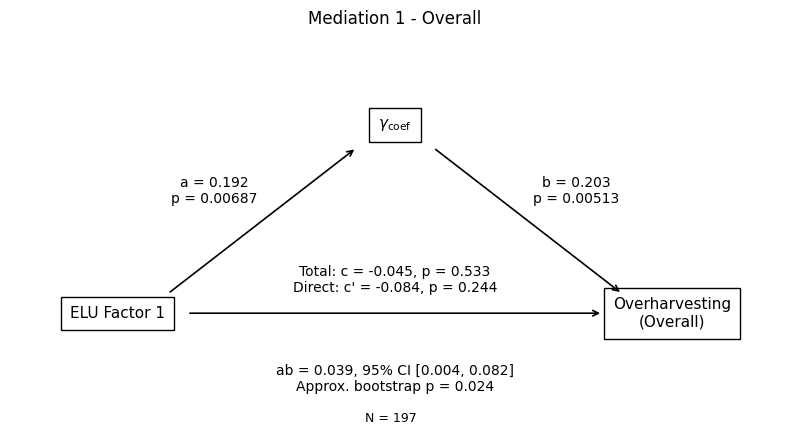

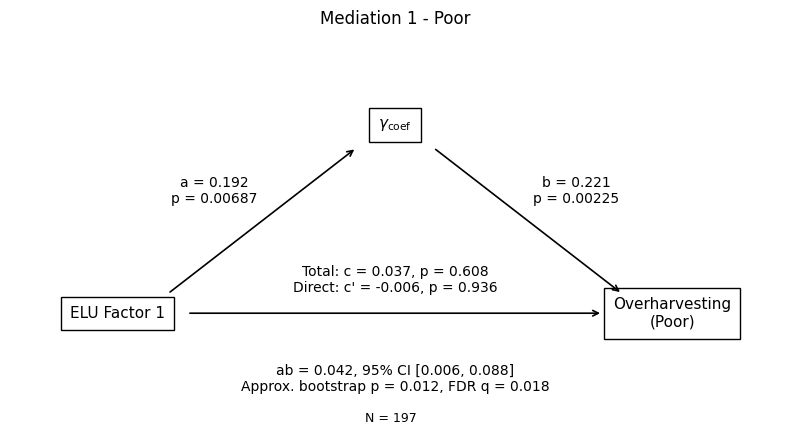

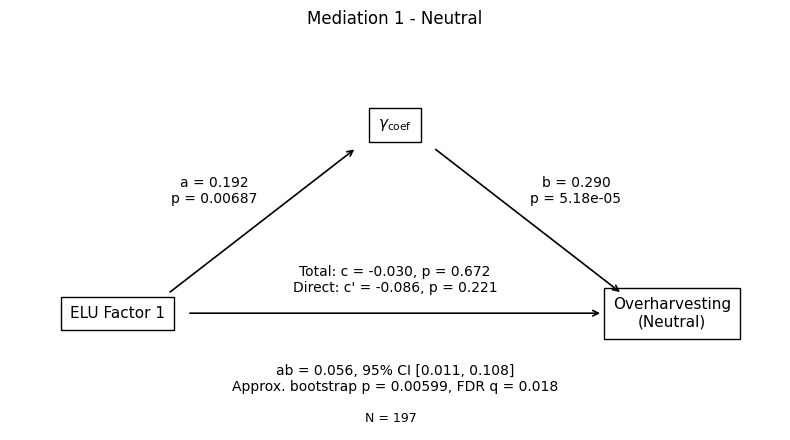

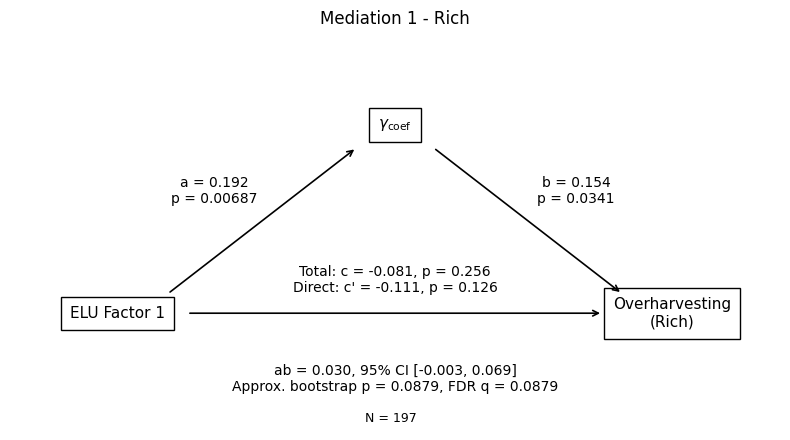


MEDIATION 2: ELU -> PCL -> gamma_coef, controlling LEC


,N,a,p_a,q_a,b,p_b,q_b,c,p_c,q_c,cp,p_cp,q_cp,ab,p_ab,q_ab,CI_low,CI_high,Sig_CI,FDR_sig_ab
Conservative,197,0.341174,0.0,0.0,0.033733,0.6762,0.7036,0.204858,0.0064,0.0064,0.193349,0.0157,0.0161,0.011509,0.6953,0.7093,-0.051024,0.077807,False,False
Stringent,197,0.398995,0.0,0.0,0.030887,0.6938,0.7036,0.205172,0.0046,0.0064,0.192848,0.0145,0.0161,0.012324,0.7093,0.7093,-0.058219,0.085481,False,False
Liberal,197,0.394305,0.0,0.0,0.029998,0.7036,0.7036,0.201704,0.0053,0.0064,0.189876,0.0161,0.0161,0.011828,0.7093,0.7093,-0.057372,0.081789,False,False


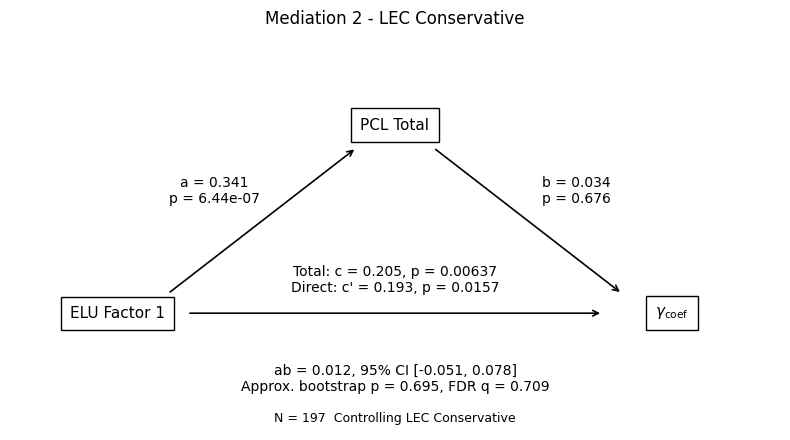

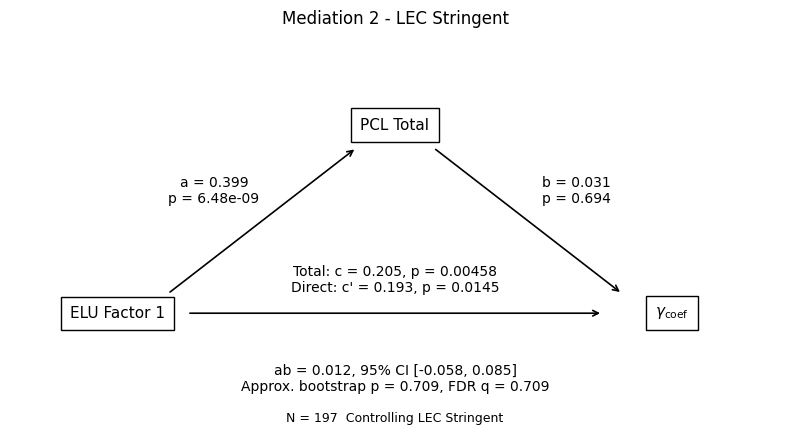

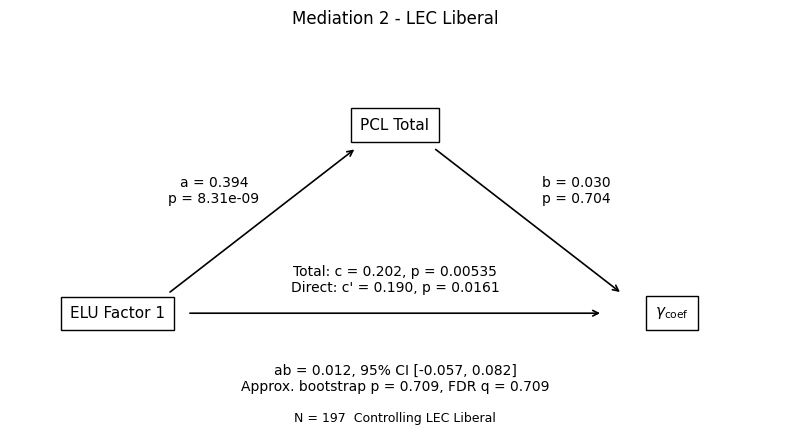

In [22]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

# ============================================================
# 1. Spearman-consistent rank-based mediation
# ============================================================

def mediation(df, x, m, y, cov=None, n_boot=1000, seed=42):
    cov = cov or []
    cols = [x, m, y] + cov

    d = df[cols].apply(pd.to_numeric, errors="coerce").dropna().copy()
    n = len(d)

    if n < 10 or (d.std(ddof=0) == 0).any():
        raise ValueError(f"Insufficient data: {cols}")

    # Rank transformation
    d = d.rank(method="average")
    d = (d - d.mean()) / d.std(ddof=0)

    def fit(outcome, predictors, data):
        X = sm.add_constant(data[predictors], has_constant="add")
        return sm.OLS(data[outcome], X).fit()

    A = fit(m, [x] + cov, d)
    B = fit(y, [x, m] + cov, d)
    C = fit(y, [x] + cov, d)

    a = A.params[x]
    b = B.params[m]
    c = C.params[x]
    cp = B.params[x]

    # Subject-level bootstrap
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)

    for i in range(n_boot):
        s = d.iloc[rng.integers(0, n, n)]

        Xa = sm.add_constant(
            s[[x] + cov], has_constant="add"
        ).to_numpy()

        Xb = sm.add_constant(
            s[[x, m] + cov], has_constant="add"
        ).to_numpy()

        ba = np.linalg.lstsq(Xa, s[m], rcond=None)[0][1]
        bb = np.linalg.lstsq(Xb, s[y], rcond=None)[0][2]

        boot[i] = ba * bb

    lo, hi = np.percentile(boot, [2.5, 97.5])

    # Approximate two-sided bootstrap sign p-value
    p_ab = min(
        1.0,
        2 * min(
            (np.sum(boot <= 0) + 1) / (n_boot + 1),
            (np.sum(boot >= 0) + 1) / (n_boot + 1)
        )
    )

    return {
        "N": n,
        "a": a, "p_a": A.pvalues[x],
        "b": b, "p_b": B.pvalues[m],
        "c": c, "p_c": C.pvalues[x],
        "cp": cp, "p_cp": B.pvalues[x],
        "ab": a * b,
        "p_ab": p_ab,
        "CI_low": lo,
        "CI_high": hi,
        "Sig_CI": (lo > 0) or (hi < 0)
    }


# ============================================================
# 2. FDR correction
# ============================================================

def correct_fdr(results, correction_groups):
    table = pd.DataFrame(results).T.copy()

    # Ensure numeric columns
    p_cols = ["p_a", "p_b", "p_c", "p_cp", "p_ab"]
    for col in p_cols:
        table[col] = pd.to_numeric(table[col])

    for col in p_cols:
        table["q_" + col[2:]] = np.nan

    for group in correction_groups:
        for col in p_cols:
            pvals = table.loc[group, col].to_numpy(dtype=float)
            _, qvals, _, _ = multipletests(
                pvals, alpha=0.05, method="fdr_bh"
            )
            table.loc[group, "q_" + col[2:]] = qvals

    table["FDR_sig_ab"] = table["q_ab"] < 0.05
    return table


def show_results(table):
    columns = [
        "N",
        "a", "p_a", "q_a",
        "b", "p_b", "q_b",
        "c", "p_c", "q_c",
        "cp", "p_cp", "q_cp",
        "ab", "p_ab", "q_ab",
        "CI_low", "CI_high",
        "Sig_CI", "FDR_sig_ab"
    ]

    display(table[columns].round(4))


# ============================================================
# 3. Mediation plots
# ============================================================

def plot_mediation(r, x, m, y, title, note=""):

    fig, ax = plt.subplots(figsize=(8, 4.5))
    fig.patch.set_facecolor("white")

    ax.set_xlim(0, 10)
    ax.set_ylim(0, 6)
    ax.axis("off")

    box = dict(
        boxstyle="square,pad=0.6",
        fc="white", ec="black", lw=1
    )

    arrow = dict(
        arrowstyle="->",
        color="black", lw=1.2
    )

    ax.text(1.4, 1.8, x, ha="center", va="center",
            fontsize=11, bbox=box)
    ax.text(5, 4.7, m, ha="center", va="center",
            fontsize=11, bbox=box)
    ax.text(8.6, 1.8, y, ha="center", va="center",
            fontsize=11, bbox=box)

    ax.annotate("", xy=(4.5, 4.35), xytext=(2.05, 2.1),
                arrowprops=arrow)
    ax.annotate("", xy=(7.95, 2.1), xytext=(5.5, 4.35),
                arrowprops=arrow)
    ax.annotate("", xy=(7.7, 1.8), xytext=(2.3, 1.8),
                arrowprops=arrow)

    ax.text(2.65, 3.5,
            f"a = {r['a']:.3f}\np = {r['p_a']:.3g}",
            ha="center", fontsize=10)

    ax.text(7.35, 3.5,
            f"b = {r['b']:.3f}\np = {r['p_b']:.3g}",
            ha="center", fontsize=10)

    ax.text(5, 2.13,
            f"Total: c = {r['c']:.3f}, p = {r['p_c']:.3g}\n"
            f"Direct: c' = {r['cp']:.3f}, p = {r['p_cp']:.3g}",
            ha="center", fontsize=10)

    q_text = (
        f", FDR q = {r['q_ab']:.3g}"
        if pd.notna(r["q_ab"]) else ""
    )

    ax.text(5, 0.6,
            f"ab = {r['ab']:.3f}, "
            f"95% CI [{r['CI_low']:.3f}, {r['CI_high']:.3f}]\n"
            f"Approx. bootstrap p = {r['p_ab']:.3g}{q_text}",
            ha="center", fontsize=10)

    ax.text(5, 0.12,
            f"N = {int(r['N'])}  {note}",
            ha="center", fontsize=9)

    ax.set_title(title, fontsize=12, pad=12)
    plt.tight_layout()
    plt.show()


# ============================================================
# 4. Mediation 1: ELU -> gamma_coef -> Overharvesting
# ============================================================

outcomes = {
    "Overall": "PRT_MVT_Overall",
    "Poor": "PRT_MVT_Poor",
    "Neutral": "PRT_MVT_Neutral",
    "Rich": "PRT_MVT_Rich"
}

results_1 = {
    name: mediation(
        df,
        x="FA_factor_1",
        m="gamma_coef",
        y=outcome
    )
    for name, outcome in outcomes.items()
}

# Correct the three environment-specific tests
table_1 = correct_fdr(
    results_1,
    correction_groups=[["Poor", "Neutral", "Rich"]]
)

# Overall is a separate primary analysis
print("\nMEDIATION 1: ELU -> gamma_coef -> Overharvesting")
show_results(table_1)

for name in outcomes:
    plot_mediation(
        table_1.loc[name],
        "ELU Factor 1",
        r"$\gamma_{\mathrm{coef}}$",
        f"Overharvesting\n({name})",
        f"Mediation 1 - {name}"
    )


# ============================================================
# 5. Mediation 2: ELU -> PCL -> gamma_coef, controlling LEC
# ============================================================

lec_scores = {
    "Conservative": "LEC_Conservative",
    "Stringent": "LEC_Stringent",
    "Liberal": "LEC_Liberal"
}

results_2 = {
    name: mediation(
        df,
        x="FA_factor_1",
        m="PCL_Total",
        y="gamma_coef",
        cov=[lec]
    )
    for name, lec in lec_scores.items()
}

table_2 = correct_fdr(
    results_2,
    correction_groups=[list(lec_scores.keys())]
)

print("\nMEDIATION 2: ELU -> PCL -> gamma_coef, controlling LEC")
show_results(table_2)

for name in lec_scores:
    plot_mediation(
        table_2.loc[name],
        "ELU Factor 1",
        "PCL Total",
        r"$\gamma_{\mathrm{coef}}$",
        f"Mediation 2 - LEC {name}",
        note=f"Controlling LEC {name}"
    )


### Early-life unpredictability is associated with uncertainty-sensitive discounting, which statistically mediates its relationship with overharvesting.



### This computational association is not accounted for by PTSD symptom severity or lifetime trauma exposure.

## Age gender breakdown

In [9]:
# ============================================================
# 7. Demographics — complete mediation sample only
# ============================================================

questionnaire_cols = [
    "FA_factor_1",
    "FA_factor_2",
    "FA_factor_3",
    "LEC_Conservative",
    "LEC_Stringent",
    "LEC_Liberal",
    "PCL_Total"
]

mediation_cols = [
    "FA_factor_1",
    "gamma_coef",
    "PRT_MVT_Overall"
]

df_complete = df.dropna(subset=questionnaire_cols).copy()
df_demo = df_complete.dropna(subset=mediation_cols).copy()


df_demo["Age"] = pd.to_numeric(
    df_demo["Age"],
    errors="coerce"
)

# ---------------- Age ----------------
age_data = df_demo["Age"].dropna()

print("\nAGE SUMMARY")
print(f"N = {len(age_data)}")
print(f"Mean = {age_data.mean():.2f}")
print(f"SD = {age_data.std():.2f}")
print(f"Median = {age_data.median():.2f}")
print(f"Range = {age_data.min():.0f}–{age_data.max():.0f}")

# ---------------- Gender ----------------
gender_data = df_demo["Gender"].fillna("Missing")

gender_summary = pd.DataFrame({
    "N": gender_data.value_counts(),
    "Percent": gender_data.value_counts(normalize=True) * 100
})

print("\nGENDER SUMMARY")
display(gender_summary.round(1))



AGE SUMMARY
N = 197
Mean = 28.45
SD = 4.56
Median = 29.00
Range = 19–35

GENDER SUMMARY


,N,Percent
Gender,,
female,98,49.7
male,97,49.2
other,2,1.0
